# CreditWise AI — Optimisation, Probability Calibration, and Explainability

This notebook tunes Random Forests with and without `loan_grade`, compares probability calibration methods, selects a candidate threshold using out-of-fold training predictions, and evaluates the selected candidate once on the existing held-out test set. It also examines subgroup metrics and model-native feature importance.

The Phase 3 test set is held out from tuning, calibration, and threshold selection. All CV/search/calibration decisions use training data only. Results are risk estimates for analysis—not loan approvals, denials, or causal explanations. SHAP explainability is added in the completed appendix below using the existing fitted candidate; it does not retrain or overwrite that model.

## 1. Inspect and validate existing artifacts

The Phase 2 configuration records the persisted combined split filenames; separate `X_train.csv` and `y_train.csv` files are not assumed. This cell verifies the actual files, schemas, target counts, original Phase 3 benchmark, and installed SHAP availability before analysis.

In [1]:
from pathlib import Path
import importlib.util
import json
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, precision_recall_curve,
)
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold, cross_val_predict,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["axes.titleweight"] = "bold"

project_root = next(
    (root for root in [Path.cwd(), *Path.cwd().parents]
     if (root / "data/processed/credit_risk_preprocessing_config.json").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate Phase 2 preprocessing configuration.")
processed_dir = project_root / "data/processed"
models_dir = project_root / "models"
reports_dir = project_root / "reports"
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)
config = json.loads((processed_dir / "credit_risk_preprocessing_config.json").read_text(encoding="utf-8"))
phase3_report = json.loads((reports_dir / "credit_risk_model_evaluation.json").read_text(encoding="utf-8"))
train_path = project_root / config["split"]["train_file"]
test_path = project_root / config["split"]["test_file"]
cleaned_path = project_root / config["cleaned_file"]
phase3_metrics_path = reports_dir / "credit_risk_model_evaluation.csv"
for path in [train_path, test_path, cleaned_path, phase3_metrics_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Expected artifact is missing: {path}")

train_frame = pd.read_csv(train_path)
test_frame = pd.read_csv(test_path)
cleaned_frame = pd.read_csv(cleaned_path)
phase3_metrics = pd.read_csv(phase3_metrics_path)
target_column = config["target_column"]
all_features = config["feature_columns"]
candidate_features = [name for name in all_features if name != "loan_grade"]
numeric_features = config["numerical_features"]
categorical_features = config["categorical_features"]
X_train = train_frame[all_features].copy()
y_train = train_frame[target_column].astype(int).copy()
X_test = test_frame[all_features].copy()
y_test = test_frame[target_column].astype(int).copy()

assert ".venv" in str(Path(sys.executable)).lower(), f"Expected project .venv, got {sys.executable}"
assert len(cleaned_frame) == config["cleaned_shape"]["rows"]
assert len(X_train) == config["split"]["train_rows"] and len(X_test) == config["split"]["test_rows"]
assert X_train.columns.tolist() == all_features == X_test.columns.tolist()
assert y_train.value_counts().sort_index().to_dict() == {int(k): v for k, v in config["split"]["train_target_counts"].items()}
assert y_test.value_counts().sort_index().to_dict() == {int(k): v for k, v in config["split"]["test_target_counts"].items()}

benchmark_name = "B_without_loan_grade__Random_Forest__default"
benchmark = phase3_metrics.loc[phase3_metrics["configuration"] == benchmark_name].iloc[0].to_dict()
benchmark_pipeline_path = project_root / phase3_report["saved_models"][benchmark_name]
benchmark_pipeline = joblib.load(benchmark_pipeline_path)
shap_available = importlib.util.find_spec("shap") is not None

print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | {sys.executable}")
print(f"Files: train={train_path.name}, test={test_path.name}, cleaned={cleaned_path.name}")
print(f"Schemas: cleaned={cleaned_frame.shape}; train={train_frame.shape}; test={test_frame.shape}")
print(f"Training target counts: {y_train.value_counts().sort_index().to_dict()}; test counts: {y_test.value_counts().sort_index().to_dict()}")
print(f"Phase 3 benchmark file: {benchmark_pipeline_path.name}; metrics: {benchmark}")
print(f"SHAP installed: {shap_available}")
if not shap_available:
    print("SHAP plots and applicant-level SHAP explanations are pending approval to install the missing shap package. No package was installed.")

Python 3.14.7 | scikit-learn 1.9.1 | D:\AI Project\CreditWiseAI\.venv\Scripts\python.exe
Files: train=credit_risk_train.csv, test=credit_risk_test.csv, cleaned=credit_risk_cleaned.csv
Schemas: cleaned=(32411, 12); train=(25928, 12); test=(6483, 12)
Training target counts: {0: 20257, 1: 5671}; test counts: {0: 5065, 1: 1418}
Phase 3 benchmark file: credit_risk_B_without_loan_grade__Random_Forest__default.joblib; metrics: {'configuration': 'B_without_loan_grade__Random_Forest__default', 'scenario': 'B_without_loan_grade', 'model': 'Random Forest', 'class_weight': 'default', 'feature_count': 10, 'accuracy': 0.9191732222736387, 'precision_default': 0.9289827255278311, 'recall_default': 0.6826516220028209, 'f1_default': 0.7869918699186992, 'roc_auc': 0.9224471155653512, 'pr_auc_average_precision': 0.8641875585273266}
SHAP installed: True


## 2. Hyperparameter optimisation using training-only CV

The completed optimization used stratified five-fold CV, `average_precision` (PR-AUC), and `random_state=42`, with eight candidates per feature scenario. This review notebook reads the saved search results instead of repeating model fits, so running it end-to-end preserves the already-trained candidate and its parameters.

In [2]:
search_summary = pd.read_csv(reports_dir / "phase4_random_forest_cv_search.csv")
phase4_report = json.loads((reports_dir / "phase4_optimization_calibration_report.json").read_text(encoding="utf-8"))
scenarios = {
    "without_loan_grade": candidate_features,
    "with_loan_grade_comparison": all_features,
}
assert len(candidate_features) == 10 and "loan_grade" not in candidate_features
assert len(all_features) == 11 and "loan_grade" in all_features
display(search_summary)
print("Loaded the completed, training-only five-fold CV search results (8 candidates per scenario, random_state=42). No estimator was refitted.")

,scenario,best_cv_average_precision,classifier__n_estimators,classifier__min_samples_split,classifier__min_samples_leaf,classifier__max_features,classifier__max_depth,classifier__class_weight
0,without_loan_grade,0.869355,300,10,8,0.7,NaN,balanced
1,with_loan_grade_comparison,0.887099,300,10,8,0.7,NaN,balanced


Loaded the completed, training-only five-fold CV search results (8 candidates per scenario, random_state=42). No estimator was refitted.


## 3. Compare uncalibrated, sigmoid, and isotonic probabilities

Calibration compares predicted probabilities with observed event frequencies. Brier score (lower is better) measures squared probability error, while Average Precision (higher is better) assesses default ranking. Out-of-fold probabilities below are produced strictly within the training split using nested stratified CV: the outer folds keep each scored row out of that model fit, and the calibrator's own CV uses only that outer-training fold. Sigmoid is conservative; isotonic is more flexible and can overfit when calibration data are limited. The training sample here is large enough to investigate isotonic, but test results—not used for selection—must still be checked.

,scenario,calibration,oof_brier_score,oof_average_precision,oof_roc_auc,outer_cv_folds,calibrator_cv_folds
0,without_loan_grade,uncalibrated,0.08231,0.86608,0.92438,3,0
1,without_loan_grade,sigmoid,0.06927,0.86176,0.92293,3,3
2,without_loan_grade,isotonic,0.06784,0.86103,0.92229,3,3
3,with_loan_grade_comparison,uncalibrated,0.07226,0.88465,0.93369,3,0
4,with_loan_grade_comparison,sigmoid,0.06095,0.88145,0.93194,3,3
5,with_loan_grade_comparison,isotonic,0.05928,0.88019,0.93115,3,3


Previously selected from nested training-only OOF predictions: isotonic (lowest Brier score).
Calibration makes predicted probabilities more interpretable as observed frequencies; it supports risk communication but does not determine approvals.


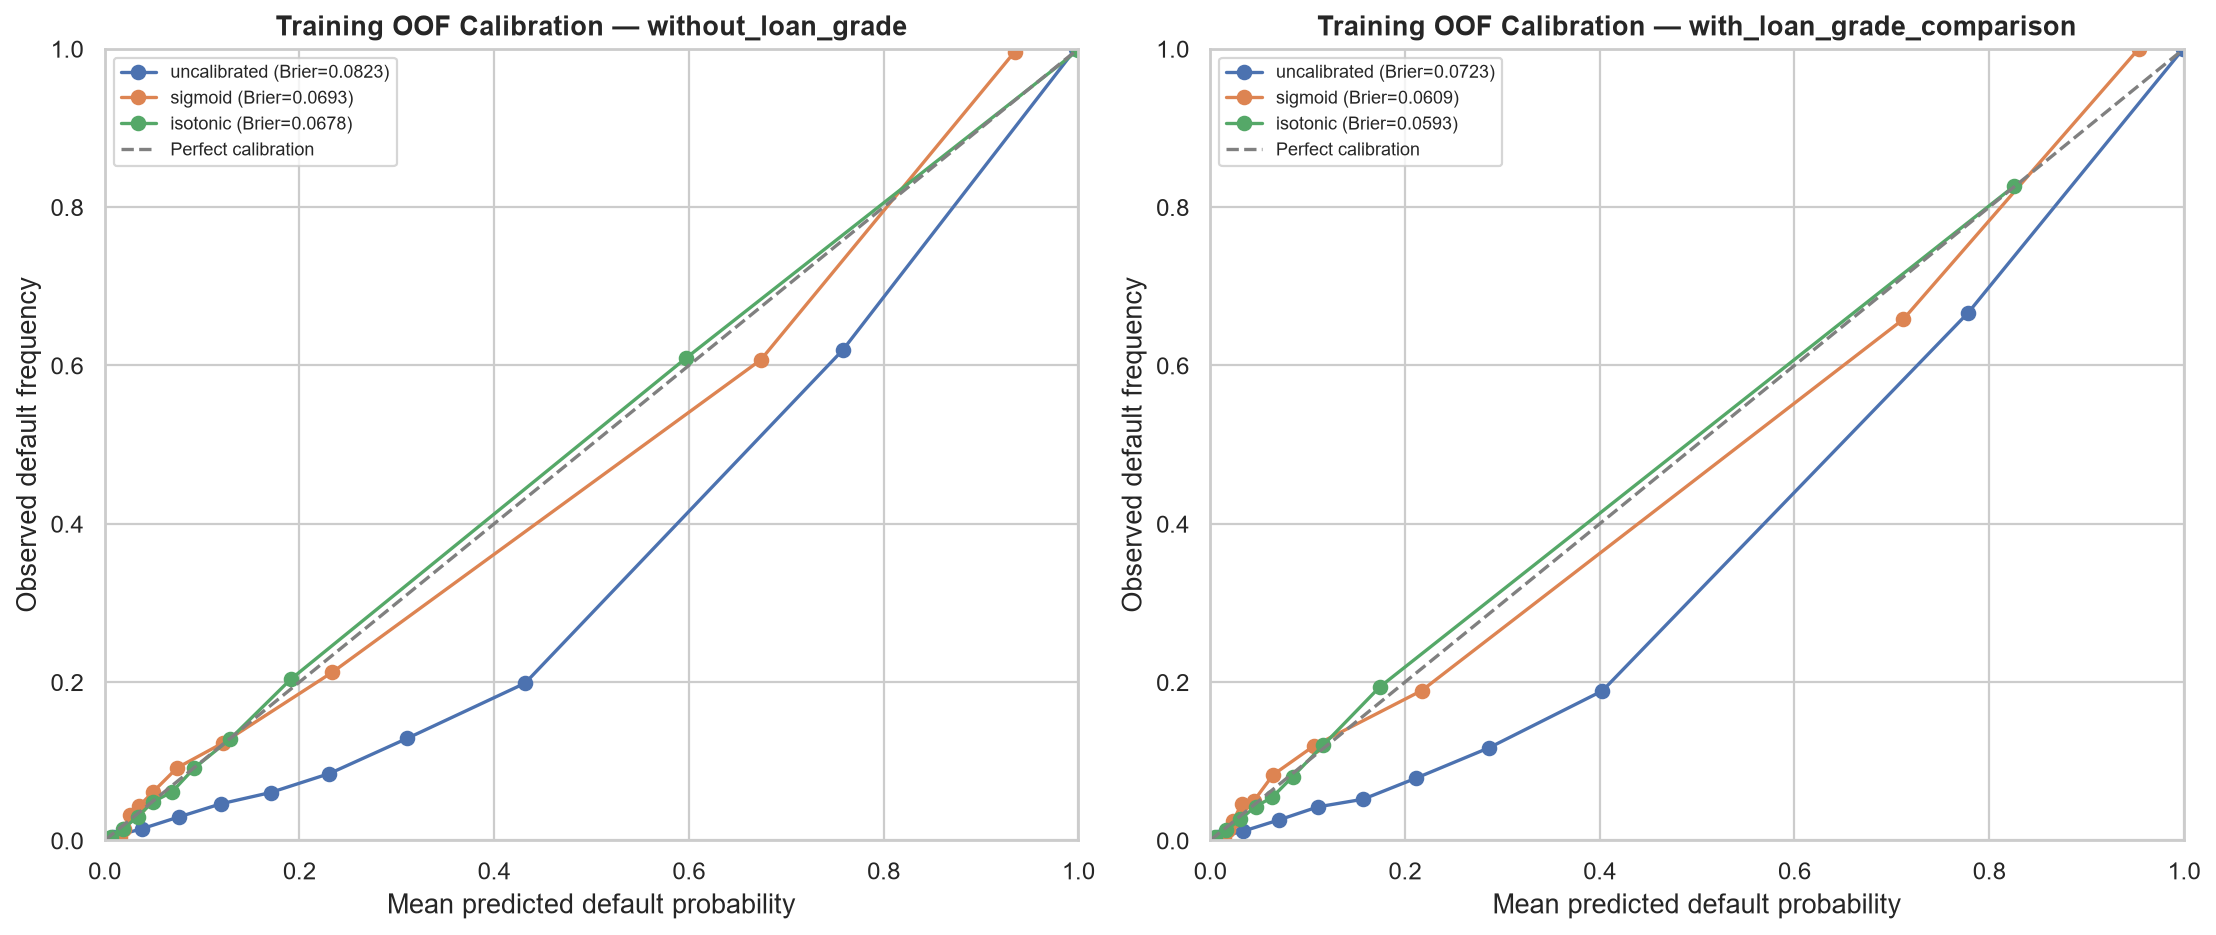

In [3]:
calibration_summary = pd.read_csv(reports_dir / "phase4_calibration_oof_comparison.csv")
calibration_plot_path = reports_dir / "phase4_training_oof_calibration.png"
from IPython.display import Image, display
display(calibration_summary.style.format({
    "oof_brier_score": "{:.5f}", "oof_average_precision": "{:.5f}", "oof_roc_auc": "{:.5f}"
}))
chosen_calibration = phase4_report["candidate_calibration_selected_on_training_oof_brier"]
print(f"Previously selected from nested training-only OOF predictions: {chosen_calibration} (lowest Brier score).")
print("Calibration makes predicted probabilities more interpretable as observed frequencies; it supports risk communication but does not determine approvals.")
display(Image(filename=str(calibration_plot_path)))

## 4. Select a decision threshold using out-of-fold training predictions

The threshold table records out-of-fold training metrics for the pre-selected candidate thresholds. This review notebook loads the saved table and chosen threshold rather than regenerating OOF predictions.

In [4]:
threshold_table = pd.read_csv(reports_dir / "phase4_training_oof_threshold_analysis.csv")
selected_threshold = float(phase4_report["candidate_threshold_selected_on_training_oof_f1"])
display(threshold_table.style.format({
    "threshold": "{:.2f}", "precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}",
    "false_positive_rate": "{:.3f}", "false_negative_rate": "{:.3f}",
    "tn": "{:,.0f}", "fp": "{:,.0f}", "fn": "{:,.0f}", "tp": "{:,.0f}",
}))
print(f"Previously selected threshold: {selected_threshold:.2f}, selected by training OOF F1 only.")
print("Lower thresholds may catch more defaults but send more non-defaults for review; higher thresholds reduce false flags but may miss more defaults.")

,threshold,precision,recall,f1,false_positive_rate,false_negative_rate,tn,fp,fn,tp
0,0.20,0.721,0.774,0.746,0.084,0.226,"18,556","1,701","1,284","4,387"
1,0.30,0.850,0.714,0.776,0.035,0.286,"19,543",714,"1,620","4,051"
2,0.40,0.908,0.684,0.780,0.019,0.316,"19,862",395,"1,791","3,880"
3,0.50,0.939,0.663,0.777,0.012,0.337,"20,014",243,"1,910","3,761"
4,0.60,0.956,0.641,0.767,0.008,0.359,"20,089",168,"2,036","3,635"
5,0.70,0.969,0.619,0.756,0.006,0.381,"20,145",112,"2,159","3,512"


Previously selected threshold: 0.40, selected by training OOF F1 only.
Lower thresholds may catch more defaults but send more non-defaults for review; higher thresholds reduce false flags but may miss more defaults.


## 5. Review the final test evaluation

The final test evaluation was completed after training-only selections were frozen. This review cell loads its saved metrics and plots and obtains test probabilities from the saved model for the subgroup and SHAP sections; no fitting or test-driven adjustment occurs.

,model,accuracy,precision_default,recall_default,f1_default,roc_auc,pr_auc_average_precision,brier_score,threshold,tn,fp,fn,tp
0,"Phase 3 Random Forest (no grade, default, unca...",0.919173,0.928983,0.682652,0.786992,0.922447,0.864188,0.067093,0.5,4991,74,450,968
1,"Phase 4 tuned + isotonic (no grade, threshold=...",0.917014,0.901460,0.696756,0.785998,0.927647,0.871071,0.063928,0.4,4957,108,430,988
2,Phase 4 tuned + isotonic (with grade compariso...,0.931822,0.973786,0.707334,0.819444,0.934528,0.886454,0.057163,0.5,5038,27,415,1003


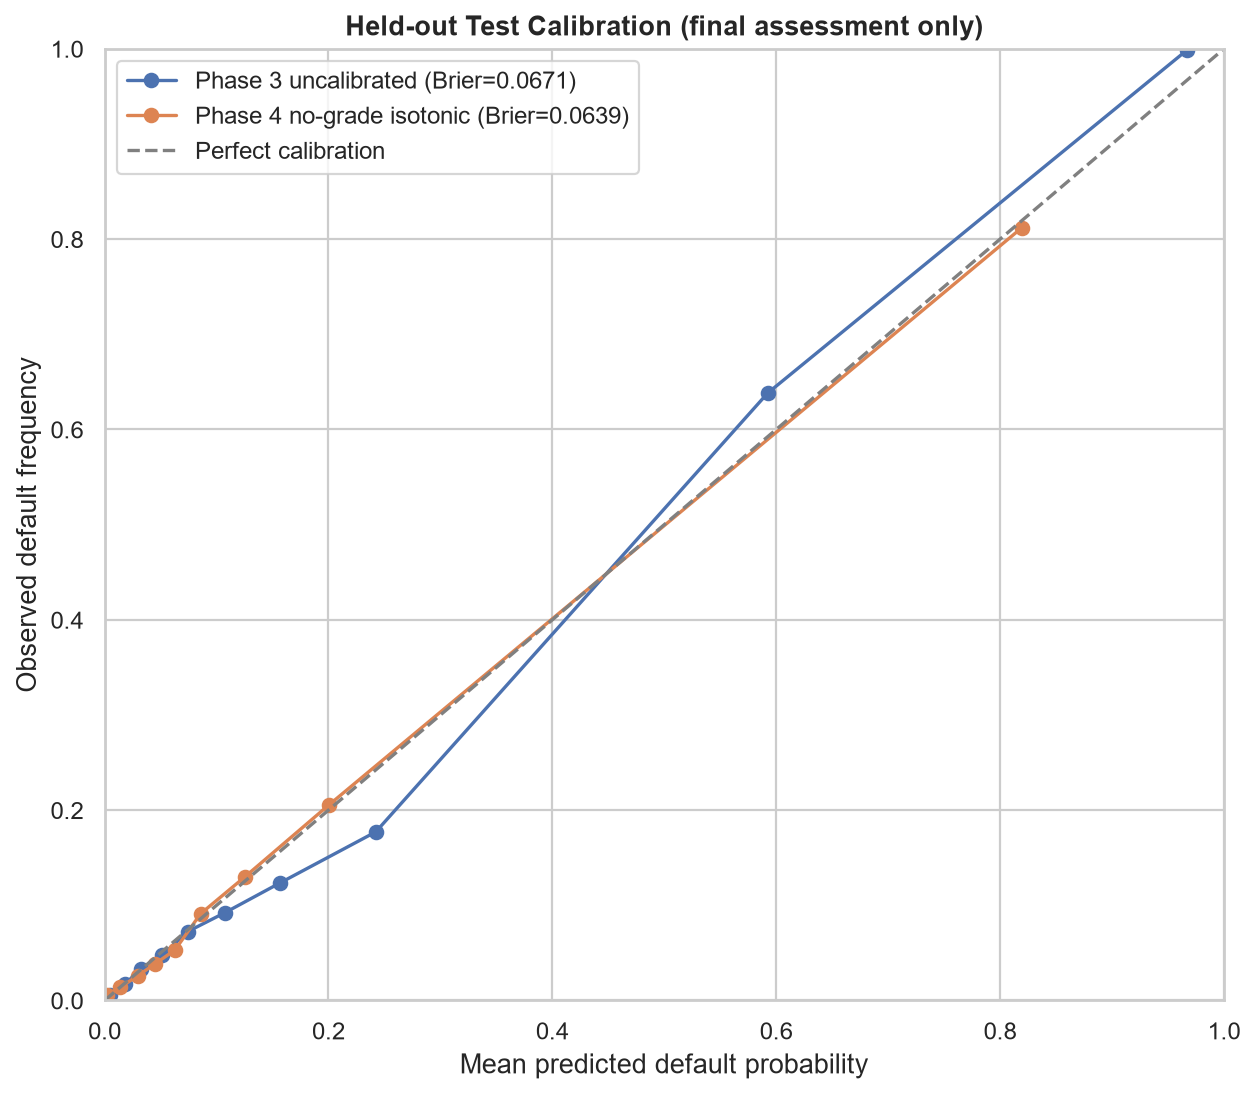

Metrics are loaded from the frozen final evaluation. Saved model pipelines were loaded for inference only; no fitting or adjustments were performed.


In [5]:
from IPython.display import Image, display
final_candidate = joblib.load(models_dir / "credit_risk_rf_optimized_calibrated_no_loan_grade.joblib")
final_grade_comparison = joblib.load(models_dir / "credit_risk_rf_optimized_calibrated_with_loan_grade_comparison.joblib")
test_comparison = pd.read_csv(reports_dir / "phase4_final_test_metrics.csv")
test_calibration_plot = reports_dir / "phase4_test_calibration_final.png"
candidate_test_prob = final_candidate.predict_proba(X_test[candidate_features])[:, 1]
grade_test_prob = final_grade_comparison.predict_proba(X_test[all_features])[:, 1]
display(test_comparison)
display(Image(filename=str(test_calibration_plot)))
print("Metrics are loaded from the frozen final evaluation. Saved model pipelines were loaded for inference only; no fitting or adjustments were performed.")

## 6. Subgroup performance assessment

Subgroup metrics use the selected no-grade model's already-computed test probabilities and the training-selected threshold. These comparisons can identify groups for further review, but are not a legal fairness assessment, proof of bias, or evidence that bias has been removed. Small groups have unstable rates; the minimum-count flag below is descriptive.

In [6]:
test_scored = X_test.copy()
test_scored["actual_default"] = y_test.to_numpy()
test_scored["predicted_probability"] = candidate_test_prob
test_scored["predicted_default"] = (candidate_test_prob >= selected_threshold).astype(int)

test_scored["age_group"] = pd.cut(
    test_scored["person_age"], bins=[-np.inf, 25, 35, 50, np.inf],
    labels=["<=25", "26-35", "36-50", "51+"],
)
test_scored["income_group"] = pd.qcut(
    test_scored["person_income"], q=4, duplicates="drop",
)

subgroup_specs = [
    ("Age group", "age_group"),
    ("Income quartile", "income_group"),
    ("Home ownership", "person_home_ownership"),
    ("Loan purpose", "loan_intent"),
]
subgroup_rows = []
minimum_group_size = 100
for group_type, column in subgroup_specs:
    for group_value, group in test_scored.groupby(column, observed=True, dropna=False):
        actual = group["actual_default"].to_numpy()
        predicted = group["predicted_default"].to_numpy()
        tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
        subgroup_rows.append({
            "group_type": group_type,
            "group": str(group_value),
            "n": len(group),
            "actual_default_rate": float(np.mean(actual)) if len(actual) else np.nan,
            "precision": precision_score(actual, predicted, zero_division=0),
            "recall_default": recall_score(actual, predicted, zero_division=0),
            "default_detection_rate": tp / (tp + fn) if tp + fn else np.nan,
            "false_positive_rate": fp / (fp + tn) if fp + tn else np.nan,
            "small_sample_flag": len(group) < minimum_group_size,
        })
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.style.format({
    "actual_default_rate": "{:.2%}", "precision": "{:.2%}",
    "recall_default": "{:.2%}", "default_detection_rate": "{:.2%}",
    "false_positive_rate": "{:.2%}", "n": "{:,.0f}",
}))
small_groups = subgroup_table.loc[subgroup_table["small_sample_flag"]]
print(f"Groups with fewer than {minimum_group_size} test examples: {len(small_groups)}. Interpret their rates cautiously.")
print("Observed subgroup differences are signals for further validation, not legal fairness conclusions or causal effects.")

,group_type,group,n,actual_default_rate,precision,recall_default,default_detection_rate,false_positive_rate,small_sample_flag
0,Age group,<=25,"2,991",23.27%,91.06%,70.26%,70.26%,2.09%,False
1,Age group,26-35,"2,764",21.13%,89.01%,69.35%,69.35%,2.29%,False
2,Age group,36-50,669,18.54%,89.47%,68.55%,68.55%,1.83%,False
3,Age group,51+,59,23.73%,100.00%,64.29%,64.29%,0.00%,True
4,Income quartile,"(4999.999, 38400.0]","1,628",39.37%,88.62%,81.44%,81.44%,6.79%,False
5,Income quartile,"(38400.0, 55000.0]","1,623",21.44%,94.42%,63.22%,63.22%,1.02%,False
6,Income quartile,"(55000.0, 80000.0]","1,681",16.89%,92.19%,62.32%,62.32%,1.07%,False
7,Income quartile,"(80000.0, 1900000.0]","1,551",9.35%,84.15%,47.59%,47.59%,0.92%,False
8,Home ownership,MORTGAGE,"2,687",12.73%,75.57%,38.89%,38.89%,1.83%,False
9,Home ownership,OTHER,28,21.43%,100.00%,50.00%,50.00%,0.00%,True


Groups with fewer than 100 test examples: 2. Interpret their rates cautiously.
Observed subgroup differences are signals for further validation, not legal fairness conclusions or causal effects.


## 7. Model-native importance and explainability limitations

The model-native Random Forest impurity importance below is a quick diagnostic; it is not causal and can favor features offering many split points. The completed SHAP analysis that follows uses the preserved calibrated candidate, explains one underlying fitted forest fold, and clearly distinguishes its raw forest probability output from the calibrated pipeline probability.

,impurity_importance
numeric__loan_percent_income,0.264486
numeric__loan_int_rate,0.262358
numeric__person_income,0.177262
categorical__person_home_ownership_RENT,0.048329
numeric__loan_amnt,0.037453
numeric__person_emp_length,0.034138
numeric__person_age,0.025874
categorical__person_home_ownership_OWN,0.022145
categorical__loan_intent_HOMEIMPROVEMENT,0.018397
numeric__cb_person_cred_hist_length,0.017091


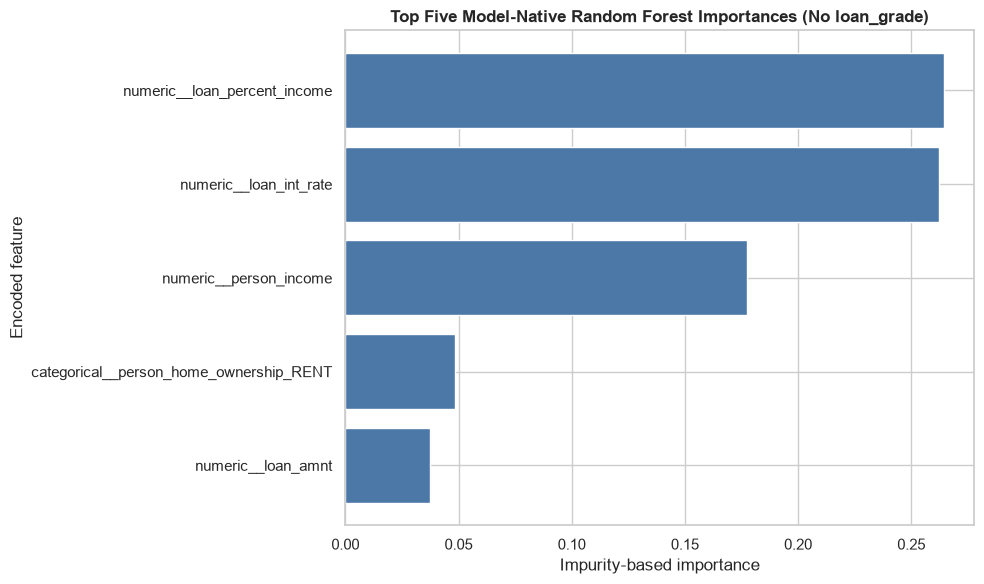

Top five model-native features:
- numeric__loan_percent_income: importance=0.2645. This indicates model reliance, not causal influence.
- numeric__loan_int_rate: importance=0.2624. This indicates model reliance, not causal influence.
- numeric__person_income: importance=0.1773. This indicates model reliance, not causal influence.
- categorical__person_home_ownership_RENT: importance=0.0483. This indicates model reliance, not causal influence.
- numeric__loan_amnt: importance=0.0375. This indicates model reliance, not causal influence.
This impurity-based importance is separate from the SHAP explanations in the next section; neither is a causal explanation.


In [7]:
selected_base_pipeline = final_candidate.calibrated_classifiers_[0].estimator
transformed_names = selected_base_pipeline.named_steps["preprocessor"].get_feature_names_out()
rf_importance = pd.Series(
    selected_base_pipeline.named_steps["classifier"].feature_importances_,
    index=transformed_names,
).sort_values(ascending=False)
top_five_importance = rf_importance.head(5).sort_values()
display(rf_importance.head(15).rename("impurity_importance").to_frame())

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_five_importance.index, top_five_importance.values, color="#4C78A8")
ax.set(title="Top Five Model-Native Random Forest Importances (No loan_grade)", xlabel="Impurity-based importance", ylabel="Encoded feature")
plt.tight_layout()
importance_plot_path = reports_dir / "phase4_random_forest_feature_importance.png"
plt.savefig(importance_plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("Top five model-native features:")
for feature_name, importance_value in rf_importance.head(5).items():
    print(f"- {feature_name}: importance={importance_value:.4f}. This indicates model reliance, not causal influence.")
print("This impurity-based importance is separate from the SHAP explanations in the next section; neither is a causal explanation.")

## 8. SHAP global and individual explanations

The candidate is a calibrated ensemble of five fold-specific pipelines. SHAP TreeExplainer is applied to the underlying Random Forest in the first fitted fold, after that fold's preprocessing. Therefore, SHAP values explain that forest's **uncalibrated class-1 probability output**, not the ensemble's isotonic-calibrated probability displayed for each profile. This distinction avoids implying that additive SHAP contributions can be applied directly to the nonlinear calibration transformation.

The global explanation uses a reproducible training-data sample; no test rows are used. Encoded one-hot feature names are retained so each category indicator is identifiable. SHAP values indicate how the fitted forest's output shifts relative to its background expectation. They are associations/model attributions, not causes or decision rules.


 26%|=====               | 135/512 [00:11<00:30]       


 29%|======              | 147/512 [00:12<00:29]       


 31%|======              | 160/512 [00:13<00:28]       


 34%|=======             | 173/512 [00:14<00:27]       


 36%|=======             | 186/512 [00:15<00:26]       


 39%|========            | 199/512 [00:16<00:25]       

... (22 outputs left out)


 96%|=================== | 492/512 [00:39<00:01]       


 99%|===================| 505/512 [00:40<00:00]       

SHAP 0.54.1; explained forest: fold 1 of 5; trees=300; sampled background=100; global explanation sample=256.
SHAP output is class-1 probability for the underlying fold forest. Maximum additivity reconstruction error: 2.37e-03.
Top 10 mean absolute SHAP features:


,feature,mean_absolute_shap_value
0,numeric__loan_int_rate,0.09627
1,numeric__loan_percent_income,0.07934
2,numeric__person_income,0.07021
3,categorical__person_home_ownership_RENT,0.03425
4,categorical__loan_intent_VENTURE,0.02732
5,categorical__person_home_ownership_OWN,0.02366
6,categorical__loan_intent_HOMEIMPROVEMENT,0.01817
7,numeric__person_emp_length,0.01570
8,categorical__cb_person_default_on_file_Y,0.01359
9,categorical__loan_intent_MEDICAL,0.01348


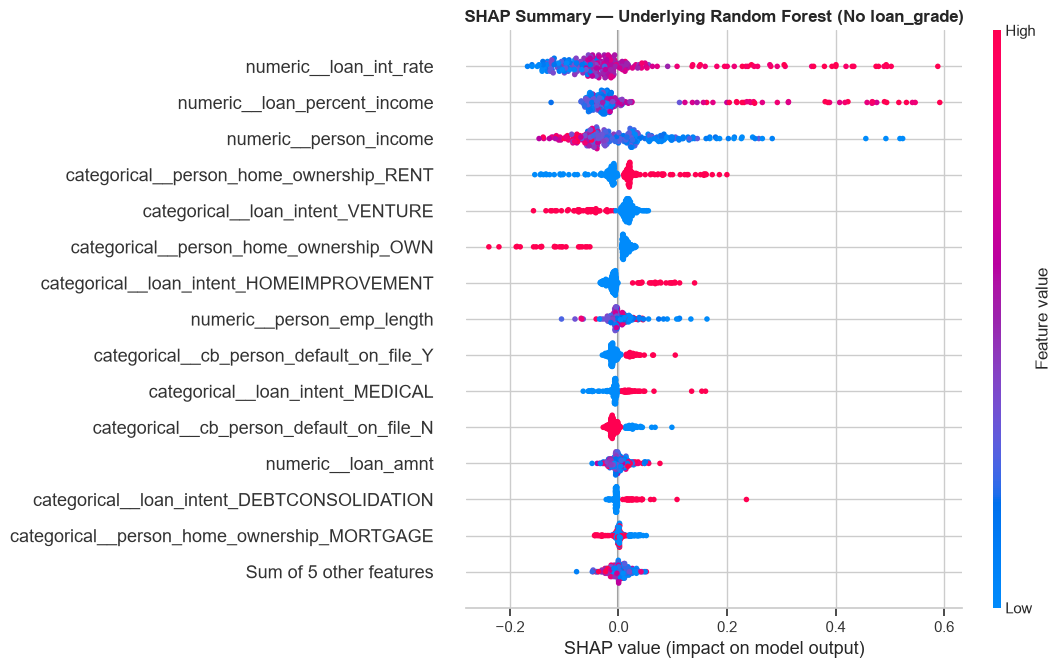

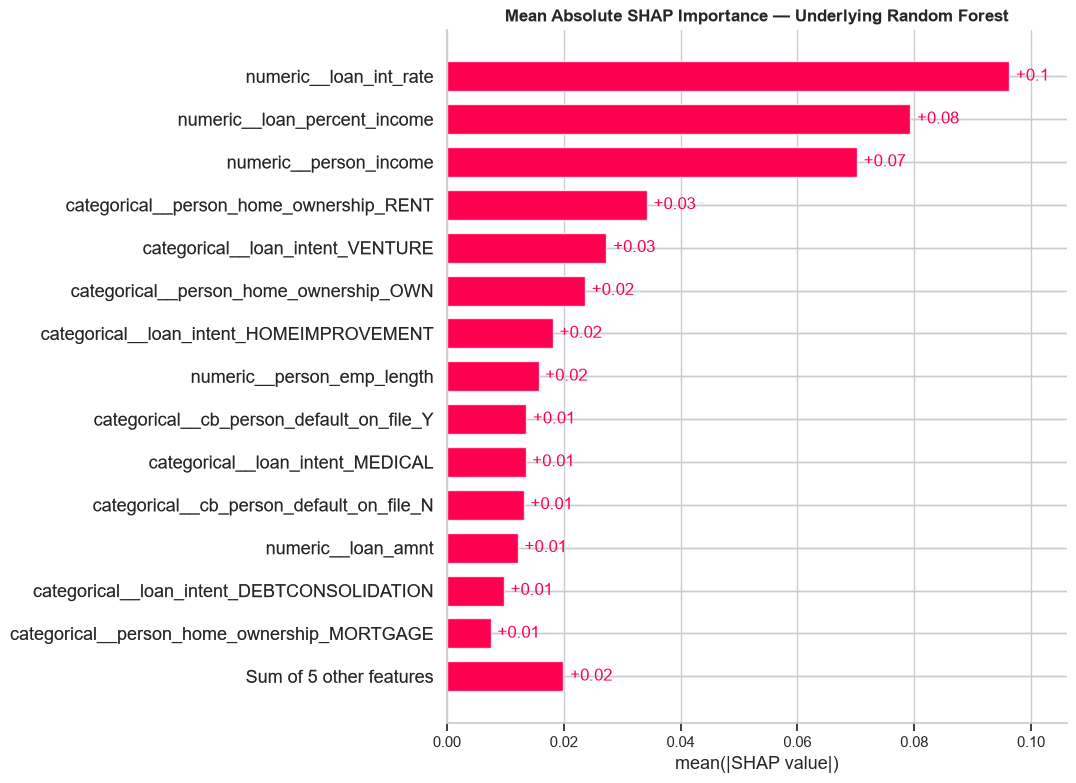

In [8]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sys
from sklearn.ensemble import RandomForestClassifier

# This appendix loads the saved model and split independently; it does not refit either.
assert ".venv" in str(Path(sys.executable)).lower(), f"Expected project .venv kernel, got {sys.executable}"
project_root = next(
    (root for root in [Path.cwd(), *Path.cwd().parents]
     if (root / "models/credit_risk_rf_optimized_calibrated_no_loan_grade.joblib").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the saved optimized candidate model.")
models_dir = project_root / "models"
reports_dir = project_root / "reports"
processed_dir = project_root / "data/processed"
config = json.loads((processed_dir / "credit_risk_preprocessing_config.json").read_text(encoding="utf-8"))
train_path = project_root / config["split"]["train_file"]
candidate_features = [name for name in config["feature_columns"] if name != "loan_grade"]
categorical_features = [name for name in config["categorical_features"] if name in candidate_features]
candidate_path = models_dir / "credit_risk_rf_optimized_calibrated_no_loan_grade.joblib"
saved_candidate = joblib.load(candidate_path)
assert isinstance(saved_candidate, __import__("sklearn.calibration").calibration.CalibratedClassifierCV)
assert saved_candidate.method == "isotonic"
assert len(saved_candidate.calibrated_classifiers_) == 5

# Explain the first already-fitted fold forest; do not refit or modify it.
explained_fold = saved_candidate.calibrated_classifiers_[0]
explained_pipeline = explained_fold.estimator
explained_preprocessor = explained_pipeline.named_steps["preprocessor"]
explained_forest = explained_pipeline.named_steps["classifier"]
assert isinstance(explained_forest, RandomForestClassifier)
shap_feature_names = explained_preprocessor.get_feature_names_out().tolist()
assert all("loan_grade" not in feature for feature in candidate_features)

phase2_train = pd.read_csv(train_path)
shap_training_features = phase2_train[candidate_features].copy()
background_raw = shap_training_features.sample(
    n=min(100, len(shap_training_features)), random_state=42
)
global_raw = shap_training_features.sample(
    n=min(256, len(shap_training_features)), random_state=2026
)
background_matrix = explained_preprocessor.transform(background_raw)
global_matrix = explained_preprocessor.transform(global_raw)

tree_explainer = shap.TreeExplainer(
    explained_forest,
    data=background_matrix,
    model_output="probability",
    feature_perturbation="interventional",
)
global_raw_explanation = tree_explainer(global_matrix, check_additivity=False)
global_class1_values = np.asarray(global_raw_explanation.values)[:, :, 1]
global_class1_base = np.asarray(global_raw_explanation.base_values)[:, 1]
global_shap = shap.Explanation(
    values=global_class1_values,
    base_values=global_class1_base,
    data=np.asarray(global_matrix),
    feature_names=shap_feature_names,
)

raw_forest_probabilities = explained_forest.predict_proba(global_matrix)[:, 1]
additive_reconstruction = global_shap.base_values + global_shap.values.sum(axis=1)
max_additivity_error = float(np.max(np.abs(additive_reconstruction - raw_forest_probabilities)))
assert max_additivity_error < 5e-3, f"SHAP contributions diverged materially from underlying RF probabilities (max error {max_additivity_error})."

shap_importance = pd.DataFrame({
    "feature": shap_feature_names,
    "mean_absolute_shap_value": np.abs(global_shap.values).mean(axis=0),
}).sort_values("mean_absolute_shap_value", ascending=False).reset_index(drop=True)
shap_importance_path = reports_dir / "phase4_shap_global_importance.csv"
shap_importance.to_csv(shap_importance_path, index=False)
print(f"SHAP {shap.__version__}; explained forest: fold 1 of 5; trees={explained_forest.n_estimators}; sampled background={len(background_raw)}; global explanation sample={len(global_raw)}.")
print(f"SHAP output is class-1 probability for the underlying fold forest. Maximum additivity reconstruction error: {max_additivity_error:.2e}.")
print("Top 10 mean absolute SHAP features:")
display(shap_importance.head(10).style.format({"mean_absolute_shap_value": "{:.5f}"}))

shap.plots.beeswarm(global_shap, max_display=15, show=False)
plt.title("SHAP Summary — Underlying Random Forest (No loan_grade)")
shap_beeswarm_path = reports_dir / "phase4_shap_summary_beeswarm.png"
plt.gcf().savefig(shap_beeswarm_path, dpi=160, bbox_inches="tight")
plt.show()

shap.plots.bar(global_shap, max_display=15, show=False)
plt.title("Mean Absolute SHAP Importance — Underlying Random Forest")
shap_bar_path = reports_dir / "phase4_shap_global_bar.png"
plt.gcf().savefig(shap_bar_path, dpi=160, bbox_inches="tight")
plt.show()

### Three representative applicant profiles

To avoid inventing borrower facts, the profiles are selected from complete records in the saved training partition, using actual observed feature values and valid dataset categories. A reproducible sample is ranked by the **calibrated candidate's** estimated probability; the records nearest the 10th, 50th, and 90th risk percentiles are described as lower, medium, and higher estimated risk. These are anonymized examples from training data, not real applicant recommendations. For each, the displayed probability is from the full calibrated candidate; the local SHAP contributions explain the first fold's uncalibrated forest output.


Lower estimated risk profile (training-sample 10% risk quantile)
Calibrated candidate estimated default probability: 0.57%
Underlying fold-1 RF raw default probability: 1.09%; SHAP baseline: 26.14%
Largest positive contributions (push the underlying forest output upward relative to its baseline):
- Person Home Ownership = OWN (observed MORTGAGE; indicator inactive): +0.0079 (0.79 percentage points of the fold forest's probability output). Model attribution, not cause.
- Emp Length (2.00): +0.0067 (0.67 percentage points of the fold forest's probability output). Model attribution, not cause.
- Loan Amnt (5,000 loan amount units): +0.0040 (0.40 percentage points of the fold forest's probability output). Model attribution, not cause.
- Cb Cred Hist Length (15.00): +0.0026 (0.26 percentage points of the fold forest's probability output). Model attribution, not cause.
- Age (39 years): +0.0020 (0.20 percentage points of the fold forest's probability output). Model attribution, not cause.
L

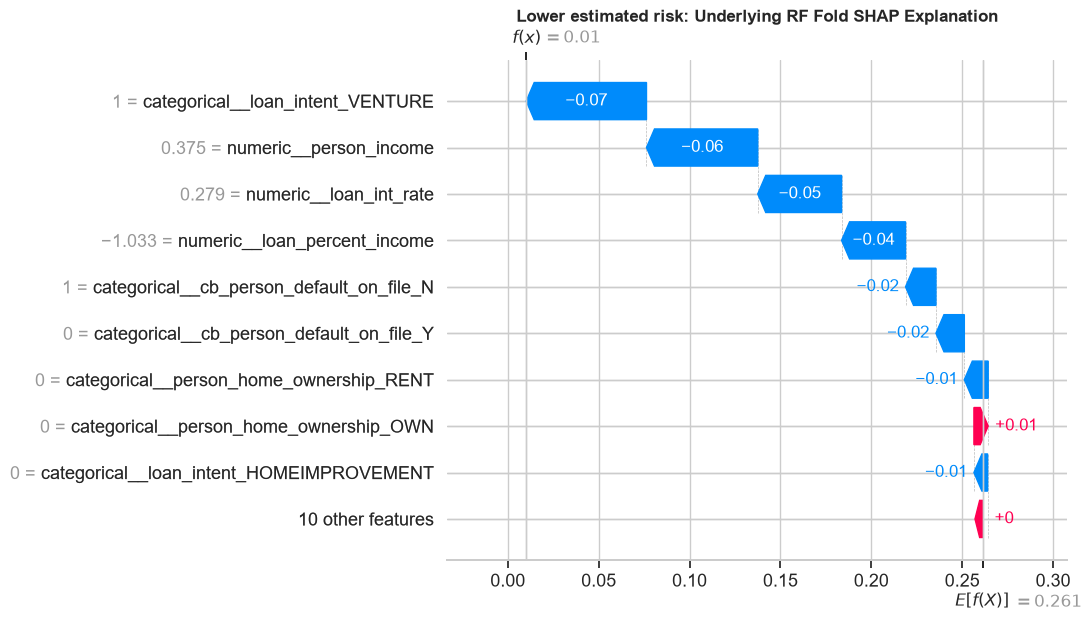


Medium estimated risk profile (training-sample 50% risk quantile)
Calibrated candidate estimated default probability: 6.56%
Underlying fold-1 RF raw default probability: 24.75%; SHAP baseline: 26.14%
Largest positive contributions (push the underlying forest output upward relative to its baseline):
- Loan Amnt (23,750 loan amount units): +0.0672 (6.72 percentage points of the fold forest's probability output). Model attribution, not cause.
- Loan Percent Income (30.0% of income): +0.0439 (4.39 percentage points of the fold forest's probability output). Model attribution, not cause.
- Loan Intent = VENTURE (observed MEDICAL; indicator inactive): +0.0275 (2.75 percentage points of the fold forest's probability output). Model attribution, not cause.
- Loan Intent = MEDICAL (observed MEDICAL; indicator active): +0.0190 (1.90 percentage points of the fold forest's probability output). Model attribution, not cause.
- Person Home Ownership = OWN (observed MORTGAGE; indicator inactive): +0.01

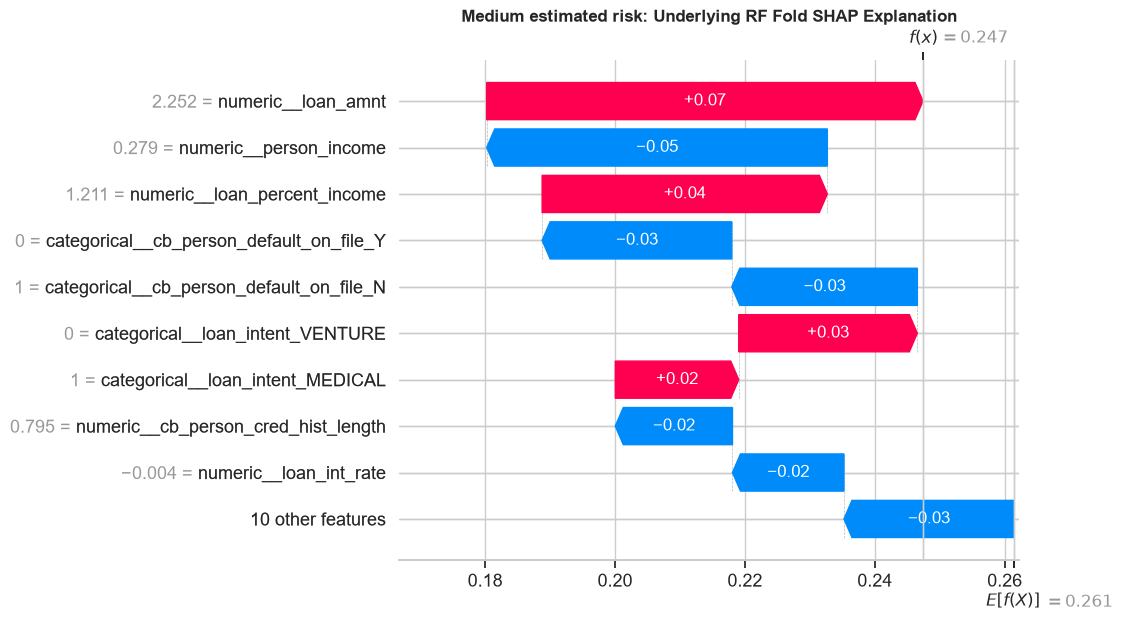


Higher estimated risk profile (training-sample 90% risk quantile)
Calibrated candidate estimated default probability: 100.00%
Underlying fold-1 RF raw default probability: 100.00%; SHAP baseline: 26.14%
Largest positive contributions (push the underlying forest output upward relative to its baseline):
- Income (14,400 annual income units): +0.4927 (49.27 percentage points of the fold forest's probability output). Model attribution, not cause.
- Loan Percent Income (28.0% of income): +0.1997 (19.97 percentage points of the fold forest's probability output). Model attribution, not cause.
- Loan Amnt (4,000 loan amount units): +0.0261 (2.61 percentage points of the fold forest's probability output). Model attribution, not cause.
- Person Home Ownership = RENT (observed RENT; indicator active): +0.0165 (1.65 percentage points of the fold forest's probability output). Model attribution, not cause.
- Loan Intent = DEBTCONSOLIDATION (observed DEBTCONSOLIDATION; indicator active): +0.0157 (1.

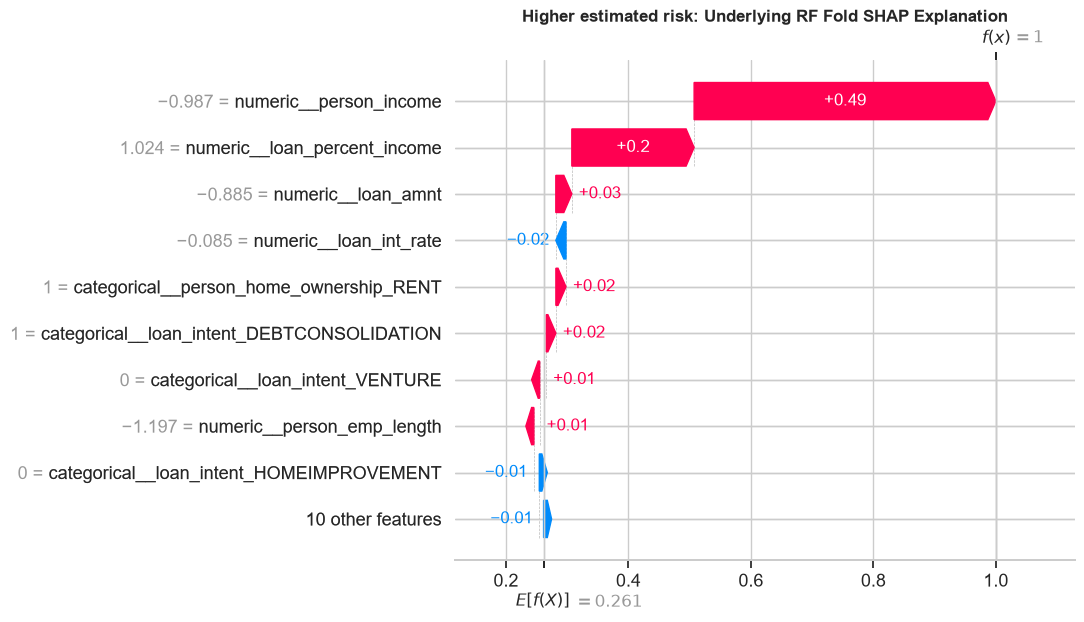

,profile,calibrated_candidate_default_probability,underlying_fold_rf_raw_default_probability,fold_rf_base_value,top_positive_contributions,top_negative_contributions
0,Lower estimated risk,0.005735,0.010887,0.261418,"[{""feature"": ""categorical__person_home_ownersh...","[{""feature"": ""categorical__loan_intent_VENTURE..."
1,Medium estimated risk,0.065630,0.247497,0.261418,"[{""feature"": ""numeric__loan_amnt"", ""display_na...","[{""feature"": ""numeric__person_income"", ""displa..."
2,Higher estimated risk,1.000000,1.000000,0.261418,"[{""feature"": ""numeric__person_income"", ""displa...","[{""feature"": ""numeric__loan_int_rate"", ""displa..."


Saved applicant profiles and explanations: D:\AI Project\CreditWiseAI\reports\phase4_shap_applicant_explanations.csv and D:\AI Project\CreditWiseAI\reports\phase4_shap_applicant_explanations.json
Applicant features are copied from anonymized observed training rows; probabilities are model estimates, not decisions or causal conclusions.


In [9]:
complete_training = shap_training_features.dropna(subset=candidate_features)
profile_pool = complete_training.sample(
    n=min(1024, len(complete_training)), random_state=42
).copy()
profile_pool["calibrated_default_probability"] = saved_candidate.predict_proba(
    profile_pool[candidate_features]
)[:, 1]

profile_quantiles = [
    ("Lower estimated risk", 0.10),
    ("Medium estimated risk", 0.50),
    ("Higher estimated risk", 0.90),
]
selected_profile_indices = []
for label, quantile in profile_quantiles:
    target_probability = profile_pool["calibrated_default_probability"].quantile(quantile)
    index = (profile_pool["calibrated_default_probability"] - target_probability).abs().idxmin()
    if index in selected_profile_indices:
        available = profile_pool.drop(index=selected_profile_indices)
        index = (available["calibrated_default_probability"] - target_probability).abs().idxmin()
    selected_profile_indices.append(index)

profile_rows = profile_pool.loc[selected_profile_indices, candidate_features].copy()
profile_matrix = explained_preprocessor.transform(profile_rows)
profile_raw_explanation = tree_explainer(profile_matrix, check_additivity=False)
profile_values = np.asarray(profile_raw_explanation.values)[:, :, 1]
profile_bases = np.asarray(profile_raw_explanation.base_values)[:, 1]
profile_rf_probabilities = explained_forest.predict_proba(profile_matrix)[:, 1]
profile_candidate_probabilities = saved_candidate.predict_proba(profile_rows)[:, 1]
profile_additivity_error = float(np.max(np.abs(profile_bases + profile_values.sum(axis=1) - profile_rf_probabilities)))
assert profile_additivity_error < 5e-3, f"Local SHAP reconstruction error is unexpectedly large: {profile_additivity_error}."

def describe_encoded_feature(feature_name, profile):
    if feature_name.startswith("numeric__"):
        raw_name = feature_name.removeprefix("numeric__")
        raw_value = profile[raw_name]
        readable_name = raw_name.replace("person_", "").replace("cb_person_", "credit history ").replace("_", " ").title()
        if raw_name == "person_income":
            value_text = f"{raw_value:,.0f} annual income units"
        elif raw_name == "loan_amnt":
            value_text = f"{raw_value:,.0f} loan amount units"
        elif raw_name == "loan_int_rate":
            value_text = f"{raw_value:.2f}% interest rate"
        elif raw_name == "loan_percent_income":
            value_text = f"{raw_value:.1%} of income"
        elif raw_name.endswith("age"):
            value_text = f"{raw_value:.0f} years"
        else:
            value_text = f"{raw_value:,.2f}"
        return readable_name, value_text
    encoded_name = feature_name.removeprefix("categorical__")
    for column in categorical_features:
        prefix = column + "_"
        if encoded_name.startswith(prefix):
            category = encoded_name[len(prefix):]
            actual_value = profile[column]
            indicator = "active" if str(actual_value) == category else "inactive"
            return f"{column.replace('_', ' ').title()} = {category}", f"observed {actual_value}; indicator {indicator}"
    return feature_name, "encoded feature"

applicant_explanations = []
for profile_number, ((label, quantile), row_index) in enumerate(zip(profile_quantiles, selected_profile_indices)):
    profile_position = profile_number
    profile = profile_rows.iloc[profile_position]
    contributions = pd.DataFrame({
        "feature": shap_feature_names,
        "shap_value": profile_values[profile_position],
    })
    positive = contributions[contributions["shap_value"] > 0].nlargest(5, "shap_value")
    negative = contributions[contributions["shap_value"] < 0].nsmallest(5, "shap_value")
    positive_items = []
    negative_items = []
    print(f"\n{label} profile (training-sample {quantile:.0%} risk quantile)")
    print(f"Calibrated candidate estimated default probability: {profile_candidate_probabilities[profile_position]:.2%}")
    print(f"Underlying fold-1 RF raw default probability: {profile_rf_probabilities[profile_position]:.2%}; SHAP baseline: {profile_bases[profile_position]:.2%}")
    print("Largest positive contributions (push the underlying forest output upward relative to its baseline):")
    for item in positive.itertuples(index=False):
        readable_name, value_text = describe_encoded_feature(item.feature, profile)
        explanation = {
            "feature": item.feature,
            "display_name": readable_name,
            "observed_value": value_text,
            "shap_contribution": float(item.shap_value),
        }
        positive_items.append(explanation)
        print(f"- {readable_name} ({value_text}): +{item.shap_value:.4f} ({item.shap_value*100:.2f} percentage points of the fold forest's probability output). Model attribution, not cause.")
    print("Largest negative contributions (push the underlying forest output downward relative to its baseline):")
    for item in negative.itertuples(index=False):
        readable_name, value_text = describe_encoded_feature(item.feature, profile)
        explanation = {
            "feature": item.feature,
            "display_name": readable_name,
            "observed_value": value_text,
            "shap_contribution": float(item.shap_value),
        }
        negative_items.append(explanation)
        print(f"- {readable_name} ({value_text}): {item.shap_value:.4f} ({item.shap_value*100:.2f} percentage points of the fold forest's probability output). Model attribution, not cause.")
    applicant_explanations.append({
        "profile": label,
        "risk_quantile_in_sample": quantile,
        "calibrated_candidate_default_probability": float(profile_candidate_probabilities[profile_position]),
        "fold_1_underlying_rf_raw_default_probability": float(profile_rf_probabilities[profile_position]),
        "fold_1_rf_base_value": float(profile_bases[profile_position]),
        "observed_features": {column: (None if pd.isna(profile[column]) else profile[column].item() if hasattr(profile[column], "item") else profile[column]) for column in candidate_features},
        "top_positive_contributions": positive_items,
        "top_negative_contributions": negative_items,
    })
    local_explanation = shap.Explanation(
        values=profile_values[profile_position],
        base_values=profile_bases[profile_position],
        data=np.asarray(profile_matrix)[profile_position],
        feature_names=shap_feature_names,
    )
    shap.plots.waterfall(local_explanation, max_display=10, show=False)
    plt.title(f"{label}: Underlying RF Fold SHAP Explanation")
    plot_path = reports_dir / f"phase4_shap_{label.lower().replace(' ', '_')}_waterfall.png"
    plt.gcf().savefig(plot_path, dpi=160, bbox_inches="tight")
    plt.show()

profile_table_rows = []
for explanation in applicant_explanations:
    row = {
        "profile": explanation["profile"],
        "sample_risk_quantile": explanation["risk_quantile_in_sample"],
        "calibrated_candidate_default_probability": explanation["calibrated_candidate_default_probability"],
        "underlying_fold_rf_raw_default_probability": explanation["fold_1_underlying_rf_raw_default_probability"],
        "fold_rf_base_value": explanation["fold_1_rf_base_value"],
        "top_positive_contributions": json.dumps(explanation["top_positive_contributions"]),
        "top_negative_contributions": json.dumps(explanation["top_negative_contributions"]),
    }
    row.update(explanation["observed_features"])
    profile_table_rows.append(row)
individual_table = pd.DataFrame(profile_table_rows)
individual_csv_path = reports_dir / "phase4_shap_applicant_explanations.csv"
individual_json_path = reports_dir / "phase4_shap_applicant_explanations.json"
individual_table.to_csv(individual_csv_path, index=False)
individual_json_path.write_text(json.dumps(applicant_explanations, indent=2), encoding="utf-8")
display(individual_table[[
    "profile", "calibrated_candidate_default_probability",
    "underlying_fold_rf_raw_default_probability", "fold_rf_base_value",
    "top_positive_contributions", "top_negative_contributions",
]])

# Update only the Phase 4 report; no model artifacts are rewritten or refitted.
phase4_report_path = reports_dir / "phase4_optimization_calibration_report.json"
phase4_saved_report = json.loads(phase4_report_path.read_text(encoding="utf-8"))
phase4_saved_report["shap"] = {
    "available": True,
    "generated": True,
    "version": shap.__version__,
    "explained_model": "first of five already-fitted fold-specific RandomForestClassifier estimators inside the calibrated candidate",
    "explained_output": "underlying fold forest class-1 raw probability; not the isotonic-calibrated ensemble probability",
    "background_sample_size": len(background_raw),
    "global_sample_size": len(global_raw),
    "random_states": {"background": 42, "global": 2026, "applicant_profile_pool": 42},
    "max_probability_additivity_error": max_additivity_error,
    "max_applicant_probability_additivity_error": profile_additivity_error,
    "top_ten_features": shap_importance.head(10).to_dict(orient="records"),
    "applicant_profiles": applicant_explanations,
    "interpretation_caveat": "SHAP attributions describe one fitted fold forest output and are not causal; they do not decompose the complete calibrated ensemble probability.",
    "artifacts": {
        "beeswarm_plot": str(shap_beeswarm_path.relative_to(project_root)),
        "global_bar_plot": str(shap_bar_path.relative_to(project_root)),
        "importance_table": str(shap_importance_path.relative_to(project_root)),
        "applicant_explanations_csv": str(individual_csv_path.relative_to(project_root)),
        "applicant_explanations_json": str(individual_json_path.relative_to(project_root)),
        "individual_waterfalls": [str((reports_dir / f"phase4_shap_{name.lower().replace(' ', '_')}_waterfall.png").relative_to(project_root)) for name, _ in profile_quantiles],
    },
}
phase4_saved_report_path = reports_dir / "phase4_optimization_calibration_report.json"
phase4_saved_report_path.write_text(json.dumps(phase4_saved_report, indent=2), encoding="utf-8")
print(f"Saved applicant profiles and explanations: {individual_csv_path} and {individual_json_path}")
print("Applicant features are copied from anonymized observed training rows; probabilities are model estimates, not decisions or causal conclusions.")

## 9. Verify preserved models and saved reports

The selected no-grade pipeline and tuned with-grade comparator are saved separately. CSV/JSON reports capture CV search, calibration, threshold analysis, final test metrics, subgroup results, and feature importance. The untouched Phase 3 artifacts are preserved.

In [10]:
candidate_model_path = models_dir / "credit_risk_rf_optimized_calibrated_no_loan_grade.joblib"
grade_model_path = models_dir / "credit_risk_rf_optimized_calibrated_with_loan_grade_comparison.joblib"
phase4_report_path = reports_dir / "phase4_optimization_calibration_report.json"
final_report = json.loads(phase4_report_path.read_text(encoding="utf-8"))
assert candidate_model_path.is_file() and grade_model_path.is_file()
assert final_report["shap"]["available"] and final_report["shap"]["generated"]
assert final_report["shap"]["version"] == shap.__version__
for relative_path in [
    final_report["shap"]["artifacts"]["beeswarm_plot"],
    final_report["shap"]["artifacts"]["global_bar_plot"],
    final_report["shap"]["artifacts"]["importance_table"],
    final_report["shap"]["artifacts"]["applicant_explanations_csv"],
    final_report["shap"]["artifacts"]["applicant_explanations_json"],
    *final_report["shap"]["artifacts"]["individual_waterfalls"],
]:
    assert (project_root / relative_path).is_file(), relative_path
print("Verified the preserved candidate and comparison pipelines; neither was refitted or overwritten.")
print(f"Verified SHAP {shap.__version__}, global plots, importance table, applicant explanations, and three waterfall plots.")
print("Search, calibration, threshold, test, and subgroup results remain loaded from their saved reports.")

Verified the preserved candidate and comparison pipelines; neither was refitted or overwritten.
Verified SHAP 0.54.1, global plots, importance table, applicant explanations, and three waterfall plots.
Search, calibration, threshold, test, and subgroup results remain loaded from their saved reports.
